# 03 · Baseline y regularización

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `rectangular-masked-v3-2026-11-22`.

Se comparan Dummy y logística L2. Se ajustan realmente seis candidatos y se seleccionan usando validación, sin consultar test.

Este cuaderno contiene el código ejecutable de la etapa, dividido en celdas con explicación. Ejecutar de arriba hacia abajo. Los notebooks se recorren del 01 al 06; los ajustes y las curvas pueden tardar varios minutos.

## 1. Librerías y ubicación del proyecto

Se cargan las bibliotecas utilizadas y se localiza la carpeta raíz. La misma celda funciona al abrir el notebook desde la raíz o desde `notebooks`. No entrena ningún modelo.

In [1]:
from pathlib import Path
import sys, json, hashlib, shutil, time, warnings, copy
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/workflow.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    cohen_kappa_score,
)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.base import clone
from xgboost import XGBClassifier
from src.features import FEATURE_COUNT, PREPROCESSING_SPEC
from src.models import SVDSubspaceClassifier


## 2. Configuración y carpetas de salida

Se fija la semilla, el orden de las cinco etiquetas y las rutas de matrices, informes y modelos. Crear estas carpetas no modifica las radiografías originales.

In [2]:
DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
LABELS = ["Normal", "Dudosa", "Leve", "Moderada", "Severa"]
SEED = 42
PROTOCOL = "rectangular-masked-v3-2026-11-22"
for folder in [DATA, REPORTS, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Protocolo:", PROTOCOL)


Proyecto: c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\repositorio-entrega\TP_4\proyecto-rodilla
Protocolo: rectangular-masked-v3-2026-11-22


## 3. Guardar resultados y mostrar las figuras

La primera función exporta JSON evitando NaN/Infinity. La segunda guarda cada gráfico y lo muestra dentro del notebook, para que el documento conserve código y salida al verse en GitHub.

In [3]:
def save_json(path, value):
    def finite(item):
        if isinstance(item, dict):
            return {k: finite(v) for k, v in item.items()}
        if isinstance(item, (list, tuple)):
            return [finite(v) for v in item]
        if isinstance(item, np.generic):
            item = item.item()
        if isinstance(item, float) and not np.isfinite(item):
            return None
        return item

    Path(path).write_text(
        json.dumps(
            finite(value), ensure_ascii=False, indent=2, allow_nan=False, default=str
        ),
        encoding="utf-8",
    )


def figure(name):
    path = FIGURES / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


## 4. Leer las matrices y definir las métricas

El cargador rechaza matrices de otra versión. La función de evaluación calcula accuracy, balanced accuracy, F1 y precisión/recall macro. F1 macro es el criterio de selección; no se ajustan transformaciones con test.

In [4]:
def arrays():
    payload = np.load(DATA / "features_arrays.npz")
    if "protocol" not in payload or str(payload["protocol"]) != PROTOCOL:
        raise ValueError(
            "Matrices de otra versión; ejecutar antes el preprocesamiento."
        )
    return payload


def score(y, pred):
    return {
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 4),
        "Balanced Acc (%)": round(balanced_accuracy_score(y, pred) * 100, 4),
        "F1 Macro": round(f1_score(y, pred, average="macro", zero_division=0), 6),
        "F1 Weighted": round(f1_score(y, pred, average="weighted", zero_division=0), 6),
        "Precision Macro": round(
            precision_score(y, pred, average="macro", zero_division=0), 6
        ),
        "Recall Macro": round(
            recall_score(y, pred, average="macro", zero_division=0), 6
        ),
    }


a = arrays()
display({k: v.shape for k, v in a.items() if k.startswith("X_")})


{'X_train_tabular': (1103, 288),
 'X_train_flat': (1103, 2304),
 'X_val_tabular': (236, 288),
 'X_val_flat': (236, 2304),
 'X_test_tabular': (237, 288),
 'X_test_flat': (237, 2304)}

## 5. Bucle completo de entrenamiento y validación

Este es el código que recorre candidatos: toma train, ejecuta `fit`, predice validación, calcula métricas y guarda modelos y resultados. El escalador/selector de cada Pipeline se ajusta solo con train. La función no accede a las entradas de test.

In [5]:
def fit_candidates(specs, filename):
    a = arrays()
    rows = []
    fitted = {}
    for name, family, kind, model in specs:
        X = a[f"X_train_{kind}"]
        V = a[f"X_val_{kind}"]
        t = time.perf_counter()
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=FutureWarning)
            model.fit(X, a["y_train"])
        metrics = score(a["y_val"], model.predict(V))
        rows.append(
            dict(
                Modelo=name,
                family=family,
                input_kind=kind,
                **metrics,
                seconds=round(time.perf_counter() - t, 2),
            )
        )
        fitted[name] = model
        print(name, metrics["F1 Macro"], flush=True)
    table = pd.DataFrame(rows).sort_values("F1 Macro", ascending=False, kind="stable")
    save_json(REPORTS / filename, table.to_dict(orient="records"))
    joblib.dump(fitted, MODELS / (filename.replace(".json", "_candidates.joblib")))
    return table


## 6. Definir Dummy y los candidatos de logística

Dummy predice la clase mayoritaria. Logística combina StandardScaler y regularización L2, compara cinco valores de C y utiliza pesos balanceados.

In [6]:
specs = [
    ("Dummy mayoritaria", "Dummy", "tabular", DummyClassifier(strategy="most_frequent"))
]

for C in [0.001, 0.01, 0.1, 1.0, 10.0]:
    specs.append(
        (
            f"Logística C={C:g}",
            "Logística",
            "tabular",
            Pipeline(
                [
                    ("scale", StandardScaler()),
                    (
                        "clf",
                        LogisticRegression(
                            C=C,
                            class_weight="balanced",
                            max_iter=3000,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),
        )
    )

print("Candidatos:", [item[0] for item in specs])


Candidatos: ['Dummy mayoritaria', 'Logística C=0.001', 'Logística C=0.01', 'Logística C=0.1', 'Logística C=1', 'Logística C=10']


## 7. Ajustar y medir el baseline

Se ejecuta el bucle completo mostrado arriba. Cada fila contiene métricas de validación y tiempo; los modelos ajustados se guardan para seleccionar posteriormente.

In [7]:
table = fit_candidates(specs, "baseline_validation.json")
display(table)


Dummy mayoritaria 0.092508
Logística C=0.001 0.544034
Logística C=0.01 0.55001
Logística C=0.1 0.512429
Logística C=1 0.482174
Logística C=10 0.444945


,Modelo,family,input_kind,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro,seconds
2,Logística C=0.01,Logística,tabular,56.3559,56.6270,0.550010,0.554682,0.539979,0.566270,0.06
1,Logística C=0.001,Logística,tabular,56.3559,56.5879,0.544034,0.549293,0.540515,0.565879,0.06
3,Logística C=0.1,Logística,tabular,53.8136,51.3924,0.512429,0.537423,0.511894,0.513924,0.08
4,Logística C=1,Logística,tabular,51.2712,48.5647,0.482174,0.514974,0.482175,0.485647,0.31
5,Logística C=10,Logística,tabular,48.3051,45.1740,0.444945,0.481653,0.442179,0.451740,0.59
0,Dummy mayoritaria,Dummy,tabular,30.0847,20.0000,0.092508,0.139154,0.060169,0.200000,0.09


## 8. Interpretar la regularización

Se grafica F1 de validación frente a C. Mayor C significa menor regularización en logística, pero el mejor valor se decide mediante validación y no por el ajuste a train.

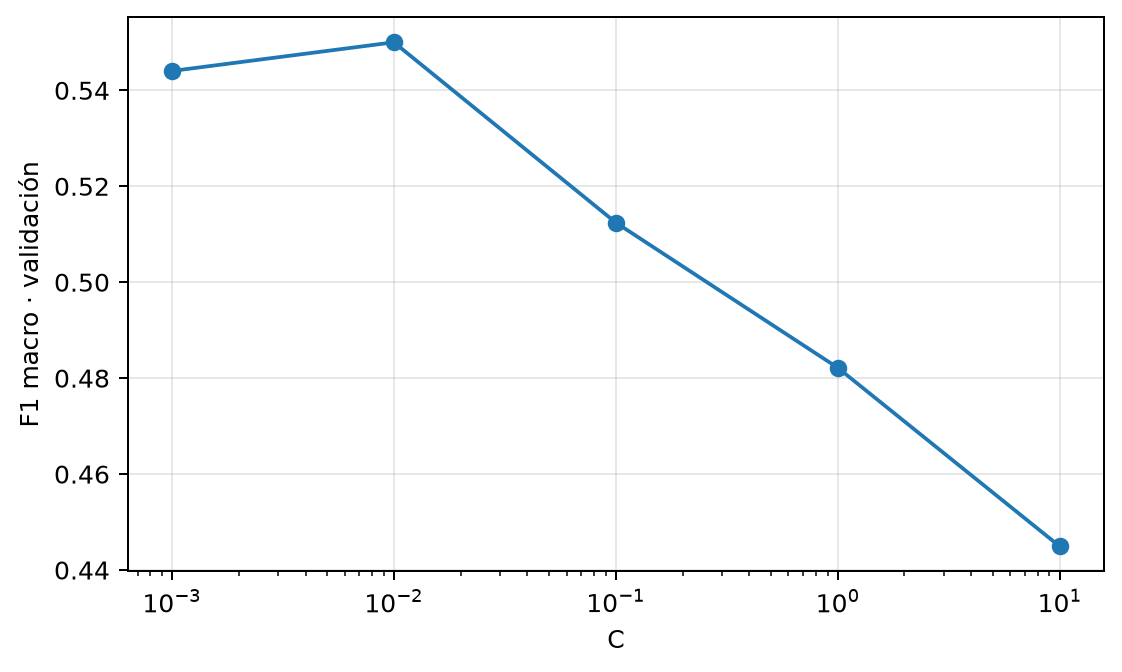

In [8]:
linear = table[table.family == "Logística"].copy()
linear["C"] = linear.Modelo.str.extract(r"C=(.*)").astype(float)
linear = linear.sort_values("C")
plt.figure(figsize=(7, 4))
plt.semilogx(linear.C, linear["F1 Macro"], "o-")
plt.xlabel("C")
plt.ylabel("F1 macro · validación")
plt.grid(alpha=0.3)
figure("baseline_regularizacion_validacion.png")
